# Анализ ассортимента методом ABC/XYZ

**Бизнес-задача:** оценить структуру ассортимента британского интернет-магазина
подарков и товаров для дома. Руководство рассматривает сокращение ~20% SKU.
Задача — предложить обоснованный список кандидатов на вывод и оценить эффект.

**Автор:** Павлов Владимир
**Дата:** 06 октября 2026

## Содержание
1. Знакомство с данными и очистка
2. Базовая картина бизнеса
3. ABC-анализ по выручке
4. XYZ-анализ
5. Матрица ABC/XYZ
6. RFM-анализ клиентов
7. Продвинутые блоки (динамический ABC, Revenue vs Quantity, концентрация AZ)
8. Итоговый список кандидатов и оценка эффекта


In [21]:
# ============================================================
# CELL 2 — Imports + config + helpers
# ============================================================
from __future__ import annotations

import os
import re
import glob
import zipfile
import warnings
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

pd.set_option('display.max_rows', 80)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

RANDOM_SEED: Final[int] = 42
PROJECT_DIR: Final[str] = '/content/drive/MyDrive/abc_xyz_project'
rng = np.random.default_rng(RANDOM_SEED)

from google.colab import drive
drive.mount('/content/drive')
os.makedirs(PROJECT_DIR, exist_ok=True)

# ВАЖНО: одинарный бэкслеш
VALID = r'^\d{5}[A-Za-z]?$'

print("VALID =", VALID)
print("Тест 22423  →", bool(re.match(VALID, '22423')))
print("Тест 85123A →", bool(re.match(VALID, '85123A')))
print("Тест POST   →", bool(re.match(VALID, 'POST')))

SERVICE_CODES = {
    'POST', 'DOT', 'M', 'C2', 'D', 'S', 'B',
    'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'PADS',
}

def is_service_code(code: str) -> bool:
    code = str(code).strip().upper()
    if code in SERVICE_CODES:
        return True
    if code.startswith('GIFT_0001'):
        return True
    return False

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VALID = ^\d{5}[A-Za-z]?$
Тест 22423  → True
Тест 85123A → True
Тест POST   → False


In [22]:
# ============================================================
# CELL 3 — Download (robust)
# ============================================================
import os
import glob
import subprocess
import sys

ZIP_PATH = '/content/online+retail+ii.zip'
DATA_DIR = '/content/data'
os.makedirs(DATA_DIR, exist_ok=True)

FILE_ID = '1QosP1syqFovZEHa9Qg8vvmu6nyw1S_Kl'

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)

existing_zips = glob.glob('/content/*.zip')
if not existing_zips:
    print("Скачиваю zip с Google Drive...")
    result = subprocess.run(
        ['gdown', FILE_ID, '-O', ZIP_PATH],
        capture_output=True, text=True,
    )
    print(result.stdout)
    if result.returncode != 0:
        print("STDERR:", result.stderr)
        raise RuntimeError("gdown не смог скачать файл. Проверь доступ к Google Drive.")

existing_zips = glob.glob('/content/*.zip')
print("Найдено zip:", existing_zips)
assert existing_zips, "Ни одного zip в /content нет — скачивание не удалось."

Найдено zip: ['/content/online+retail+ii.zip']


In [23]:
# ============================================================
# CELL 4 — Load + clean (с диагностикой на каждом шаге)
# ============================================================
import re
import zipfile

# 1) Распакуем найденный zip
zip_candidates = glob.glob('/content/*.zip')
assert zip_candidates, "Нет zip в /content — перезапусти CELL 3."
zip_path = ZIP_PATH if os.path.exists(ZIP_PATH) else zip_candidates[0]
print(f"Использую zip: {zip_path}")

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(DATA_DIR)
    print("Внутри zip:", z.namelist())

# 2) Найдём .xlsx
xlsx_candidates = glob.glob(f'{DATA_DIR}/**/*.xlsx', recursive=True)
assert xlsx_candidates, f"В {DATA_DIR} нет .xlsx. Содержимое: {os.listdir(DATA_DIR)}"
file_path = xlsx_candidates[0]
print(f"Читаю Excel: {file_path}")

df_0910 = pd.read_excel(file_path, sheet_name='Year 2009-2010', engine='openpyxl')
df_1011 = pd.read_excel(file_path, sheet_name='Year 2010-2011', engine='openpyxl')

df = pd.concat([df_0910, df_1011], ignore_index=True)
df = df.rename(columns={
    'Invoice': 'InvoiceNo',
    'Price': 'UnitPrice',
    'Customer ID': 'CustomerID',
})
df['InvoiceNo']    = df['InvoiceNo'].astype(str)
df['StockCode']    = df['StockCode'].astype(str).str.strip().str.upper()
df['Description']  = df['Description'].astype(str).str.strip()
df['CustomerID']   = df['CustomerID'].astype('Int64')
df['InvoiceDate']  = pd.to_datetime(df['InvoiceDate'])

df = df.drop_duplicates().reset_index(drop=True)
df.to_parquet(os.path.join(PROJECT_DIR, 'raw.parquet'), index=False)
print(f"Загружено после дедупликации: {len(df):,} строк")

# --- Ограничение периода ---
PERIOD_START = pd.Timestamp('2010-12-01 00:00:00')
PERIOD_END   = pd.Timestamp('2011-11-30 23:59:59')

df_period = df[
    (df['InvoiceDate'] >= PERIOD_START) &
    (df['InvoiceDate'] <= PERIOD_END)
].copy().reset_index(drop=True)
df_period['is_cancellation'] = df_period['InvoiceNo'].str.startswith('C')
df_period['is_service']      = df_period['StockCode'].apply(is_service_code)
print(f"В периоде: {len(df_period):,}")

# --- Базовая очистка ---
df_sales = df_period[
    (df_period['Quantity'] > 0) &
    (df_period['UnitPrice'] > 0) &
    (~df_period['is_service'])
].copy()
df_sales['Revenue'] = df_sales['Quantity'] * df_sales['UnitPrice']
n_before_phantom = len(df_sales)
print(f"После базовой очистки: {n_before_phantom:,}")

# --- Фантомные отмены: удаляем ТОЛЬКО совпавшие sale-строки ---
cancellations = df_period[df_period['is_cancellation']].copy()
cancellations['abs_qty'] = cancellations['Quantity'].abs()
cancellations['date']    = cancellations['InvoiceDate'].dt.date

sales_tmp = df_sales.reset_index(drop=True).copy()
sales_tmp['date']    = sales_tmp['InvoiceDate'].dt.date
sales_tmp['_row_id'] = np.arange(len(sales_tmp))

cancel_keys = (
    cancellations
    .dropna(subset=['CustomerID'])
    .groupby(['CustomerID', 'StockCode', 'abs_qty', 'date'])
    .size()
    .reset_index(name='n_cancel')
)

merged = sales_tmp.merge(
    cancel_keys,
    left_on=['CustomerID', 'StockCode', 'Quantity', 'date'],
    right_on=['CustomerID', 'StockCode', 'abs_qty', 'date'],
    how='inner',
)

to_remove = set()
for _, group in merged.groupby(['CustomerID', 'StockCode', 'Quantity', 'date']):
    n_cancel   = int(group['n_cancel'].iloc[0])
    unique_ids = group['_row_id'].drop_duplicates().tolist()
    to_remove.update(unique_ids[:n_cancel])

df_sales = (
    sales_tmp
    .drop(columns=['date', '_row_id'])
    .drop(index=list(to_remove))
    .reset_index(drop=True)
)
print(f"Удалено sale-строк фантомных отмен: {len(to_remove):,}")

# --- Финальная валидация StockCode ---
mask = df_sales['StockCode'].astype(str).str.match(VALID)
n_match = int(mask.sum())
print(f"Строк до regex-фильтра:  {len(df_sales):,}")
print(f"Строк после regex:       {n_match:,}")
print("Примеры StockCode (до фильтра):", df_sales['StockCode'].drop_duplicates().head(10).tolist())

assert n_match > 0, (
    "Все StockCode отфильтрованы regex — проверь VALID. "
    "Скорее всего двойной бэкслеш: должно быть r'^\\d{5}[A-Za-z]?$'"
)

df_sales = df_sales[mask].copy()
df_sales = df_sales.drop(columns=['is_cancellation', 'is_service'], errors='ignore')
df_sales = df_sales.reset_index(drop=True)

df_sales.to_parquet(os.path.join(PROJECT_DIR, 'sales_clean.parquet'), index=False)

print("=== ИТОГ ОЧИСТКИ ===")
print(f"Было (после дедупа):         {len(df):>10,} строк")
print(f"В периоде:                   {len(df_period):>10,} строк")
print(f"После базовой очистки:       {n_before_phantom:>10,} строк")
print(f"Совпавших отмен (фантомных): {len(merged):>10,} пар")
print(f"Удалено sale-строк:          {len(to_remove):>10,}")
print(f"После фантомных отмен:       {len(df_sales):>10,} строк")
print(f"Уникальных SKU (final):      {df_sales['StockCode'].nunique():>10,}")
print(f"Уникальных заказов:          {df_sales['InvoiceNo'].nunique():>10,}")
print(f"Уникальных клиентов:         {df_sales['CustomerID'].dropna().nunique():>10,}")
print(f"Выручка (final):             £{df_sales['Revenue'].sum():>12,.2f}")
print(f"Единиц товара:               {df_sales['Quantity'].sum():>10,}")
print(f"Даты: {df_sales['InvoiceDate'].min().date()} → {df_sales['InvoiceDate'].max().date()}")

Использую zip: /content/online+retail+ii.zip
Внутри zip: ['online_retail_II.xlsx']
Читаю Excel: /content/data/online_retail_II.xlsx
Загружено после дедупликации: 1,033,036 строк
В периоде: 511,395
После базовой очистки: 497,784
Удалено sale-строк фантомных отмен: 722
Строк до regex-фильтра:  497,062
Строк после regex:       496,657
Примеры StockCode (до фильтра): ['85123A', '71053', '84406B', '84029G', '84029E', '22752', '21730', '22633', '22632', '22960']
=== ИТОГ ОЧИСТКИ ===
Было (после дедупа):          1,033,036 строк
В периоде:                      511,395 строк
После базовой очистки:          497,784 строк
Совпавших отмен (фантомных):        826 пар
Удалено sale-строк:                 722
После фантомных отмен:          496,657 строк
Уникальных SKU (final):           3,788
Уникальных заказов:              18,859
Уникальных клиентов:              4,291
Выручка (final):             £9,471,200.61
Единиц товара:                5,138,368
Даты: 2010-12-01 → 2011-11-30


## Базовая картина бизнеса

Период анализа: 2010-12-01 → 2011-11-30 (12 полных месяцев).
Ключевая сезонность: пик в ноябре (15.2% выручки), спад в феврале и апреле.

In [24]:
# ============================================================
# CELL 5 — Basic business metrics
# ============================================================
total_revenue = df_sales['Revenue'].sum()
total_units   = df_sales['Quantity'].sum()
n_skus        = df_sales['StockCode'].nunique()
n_invoices    = df_sales['InvoiceNo'].nunique()
n_customers   = df_sales['CustomerID'].dropna().nunique()

invoice_value   = df_sales.groupby('InvoiceNo')['Revenue'].sum()
avg_order_value = invoice_value.mean()
avg_items_order = len(df_sales) / n_invoices
avg_price_unit  = total_revenue / total_units

print(f"Уникальных SKU:            {n_skus:,}")
print(f"Уникальных заказов:        {n_invoices:,}")
print(f"Уникальных клиентов:       {n_customers:,}")
print(f"Выручка:                   £{total_revenue:,.2f}")
print(f"Количество единиц:         {total_units:,}")
print(f"Средний чек:               £{avg_order_value:,.2f}")
print(f"Средних позиций в заказе:  {avg_items_order:.2f}")
print(f"Средняя цена единицы:      £{avg_price_unit:.2f}")

monthly = df_sales.groupby(df_sales['InvoiceDate'].dt.to_period('M')).agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Units=('Quantity', 'sum'),
    SKUs=('StockCode', 'nunique'),
).round(2)
monthly['AvgOrderValue']   = (monthly['Revenue'] / monthly['Orders']).round(2)
monthly['Revenue_share_%'] = (monthly['Revenue'] / monthly['Revenue'].sum() * 100).round(1)
print("\nВыручка по месяцам:")
print(monthly)

Уникальных SKU:            3,788
Уникальных заказов:        18,859
Уникальных клиентов:       4,291
Выручка:                   £9,471,200.61
Количество единиц:         5,138,368
Средний чек:               £502.21
Средних позиций в заказе:  26.34
Средняя цена единицы:      £1.84

Выручка по месяцам:
                 Revenue  Orders   Units  SKUs  AvgOrderValue  Revenue_share_%
InvoiceDate                                                                   
2010-12       770,725.14    1539  355985  2718         500.80             8.10
2011-01       590,820.88    1072  311587  2523         551.14             6.20
2011-02       506,792.32    1089  282450  2342         465.37             5.40
2011-03       686,085.10    1435  374785  2445         478.11             7.20
2011-04       493,757.37    1224  299031  2406         403.40             5.20
2011-05       737,295.35    1660  393742  2404         444.15             7.80
2011-06       735,279.59    1514  387394  2577         485.65       

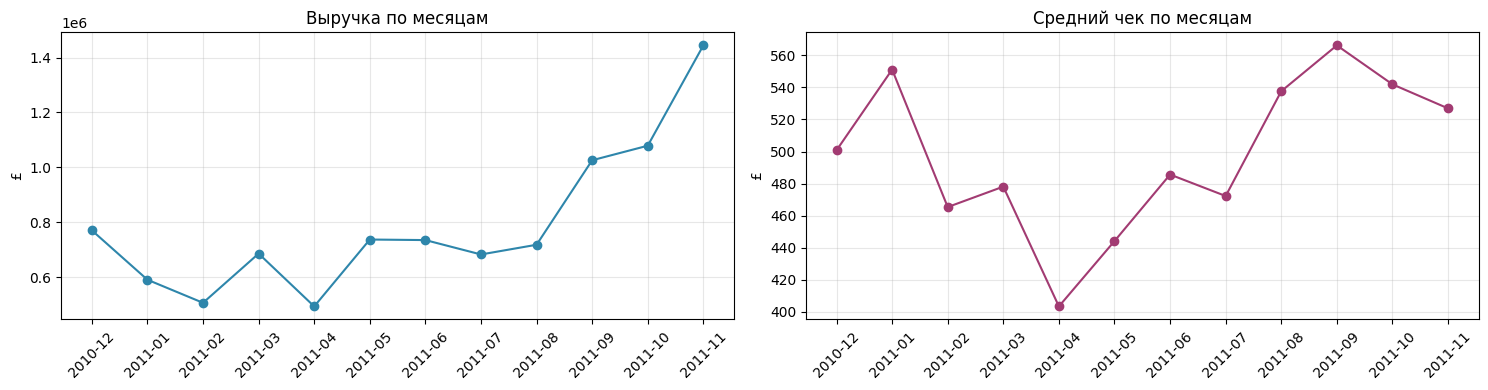

In [25]:
# ============================================================
# CELL 6 — Monthly dynamics plot
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(monthly.index.astype(str), monthly['Revenue'], marker='o', color='#2E86AB')
axes[0].set_title('Выручка по месяцам')
axes[0].set_ylabel('£')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)

axes[1].plot(monthly.index.astype(str), monthly['AvgOrderValue'], marker='o', color='#A23B72')
axes[1].set_title('Средний чек по месяцам')
axes[1].set_ylabel('£')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## ABC-анализ по выручке

Классическая разбивка по накопленной доле выручки:
- **A**: до 80% накопленной выручки — ядро ассортимента
- **B**: 80–95% — средний слой
- **C**: 95–100% — хвост, кандидаты на вывод

In [26]:
# ============================================================
# CELL 7 — ABC by revenue
# ============================================================
sku_abc = (
    df_sales
    .groupby('StockCode')
    .agg(
        Revenue=('Revenue', 'sum'),
        Units=('Quantity', 'sum'),
        Orders=('InvoiceNo', 'nunique'),
        Customers=('CustomerID', 'nunique'),
    )
    .reset_index()
    .sort_values('Revenue', ascending=False)
    .reset_index(drop=True)
)

sku_abc['rank']        = sku_abc.index + 1
sku_abc['share_%']     = sku_abc['Revenue'] / sku_abc['Revenue'].sum() * 100
sku_abc['cum_share_%'] = sku_abc['share_%'].cumsum()

def classify_abc(cum_share):
    if cum_share <= 80: return 'A'
    if cum_share <= 95: return 'B'
    return 'C'

sku_abc['ABC'] = sku_abc['cum_share_%'].apply(classify_abc)

abc_summary = (
    sku_abc
    .groupby('ABC')
    .agg(SKUs=('StockCode', 'count'),
         Revenue=('Revenue', 'sum'),
         Units=('Units', 'sum'))
    .reset_index()
)
abc_summary['SKU_share_%']     = (abc_summary['SKUs']    / abc_summary['SKUs'].sum()    * 100).round(1)
abc_summary['Revenue_share_%'] = (abc_summary['Revenue'] / abc_summary['Revenue'].sum() * 100).round(1)
abc_summary['Units_share_%']   = (abc_summary['Units']   / abc_summary['Units'].sum()   * 100).round(1)
abc_summary = abc_summary.sort_values('ABC')

print("=== Сводка ABC ===")
print(abc_summary.to_string(index=False))
print("\nТоп-10 SKU по выручке:")
print(sku_abc[['rank','StockCode','Revenue','cum_share_%','ABC']].head(10).to_string(index=False))

=== Сводка ABC ===
ABC  SKUs      Revenue   Units  SKU_share_%  Revenue_share_%  Units_share_%
  A   831 7,575,184.43 3465158        21.90            80.00          67.40
  B   962 1,422,161.28 1191247        25.40            15.00          23.20
  C  1995   473,854.90  481963        52.70             5.00           9.40

Топ-10 SKU по выручке:
 rank StockCode    Revenue  cum_share_% ABC
    1     22423 166,623.42         1.76   A
    2    85123A  99,344.60         2.81   A
    3     47566  98,467.35         3.85   A
    4    85099B  90,800.23         4.81   A
    5     23084  57,241.57         5.41   A
    6     22086  57,171.18         6.01   A
    7     84879  56,756.43         6.61   A
    8     79321  51,433.62         7.16   A
    9     22502  51,087.97         7.70   A
   10     22197  45,756.47         8.18   A


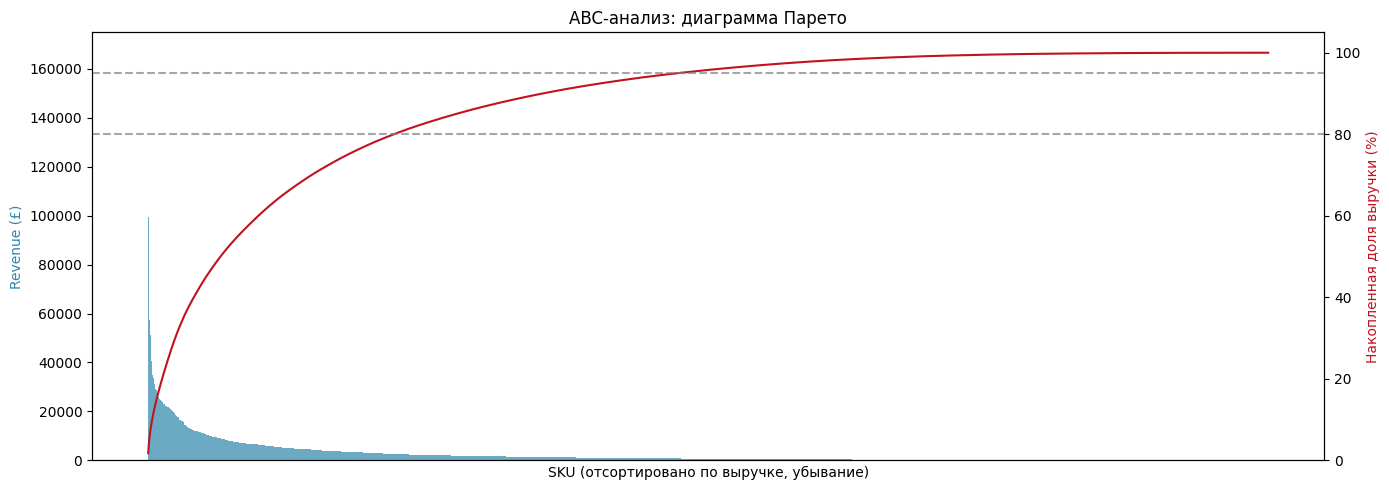

In [27]:
# ============================================================
# CELL 8 — Pareto chart
# ============================================================
fig, ax1 = plt.subplots(figsize=(14, 5))
x = range(len(sku_abc))

ax1.bar(x, sku_abc['Revenue'], color='#2E86AB', alpha=0.7, width=1.0)
ax1.set_ylabel('Revenue (£)', color='#2E86AB')
ax1.set_xlabel('SKU (отсортировано по выручке, убывание)')
ax1.set_xticks([])

ax2 = ax1.twinx()
ax2.plot(x, sku_abc['cum_share_%'], color='#C1121F', linewidth=1.5)
ax2.axhline(80, color='gray', linestyle='--', alpha=0.7)
ax2.axhline(95, color='gray', linestyle='--', alpha=0.7)
ax2.set_ylabel('Накопленная доля выручки (%)', color='#C1121F')
ax2.set_ylim(0, 105)

plt.title('ABC-анализ: диаграмма Парето')
plt.tight_layout()
plt.show()

## XYZ-анализ

Метрика — **коэффициент вариации** (CV = σ/μ) месячной выручки SKU за 12 месяцев.
SKU, не продававшиеся в каком-то месяце, получают 0 (не NaN) — иначе CV искажается.

**Классические пороги** (10% / 25%) слишком строги для розницы с сезонностью:
почти всё уйдёт в Z. Используем **адаптированные**:
- **X**: CV ≤ 0.5 — стабильный спрос
- **Y**: 0.5 < CV ≤ 1.0 — колеблющийся
- **Z**: CV > 1.0 — нерегулярный

In [28]:
# ============================================================
# CELL 9 — XYZ analysis
# ============================================================
pivot = df_sales.pivot_table(
    index='StockCode',
    columns=df_sales['InvoiceDate'].dt.to_period('M'),
    values='Revenue',
    aggfunc='sum',
).fillna(0)   # отсутствие продаж = 0, НЕ NaN

xyz = pivot.std(axis=1).to_frame('std')
xyz['mean'] = pivot.mean(axis=1)
xyz['cv']   = xyz['std'] / xyz['mean']

def classify_xyz(cv):
    if cv <= 0.5: return 'X'
    if cv <= 1.0: return 'Y'
    return 'Z'

xyz['XYZ'] = xyz['cv'].apply(classify_xyz)

xyz_summary = (
    xyz
    .groupby('XYZ')
    .agg(SKUs=('cv', 'count'), CV_mean=('cv', 'mean'), CV_median=('cv', 'median'))
    .reset_index()
)
xyz_summary['SKU_share_%'] = (xyz_summary['SKUs'] / xyz_summary['SKUs'].sum() * 100).round(1)
xyz_summary = xyz_summary.sort_values('XYZ')

print("=== Сводка XYZ ===")
print(xyz_summary.round(3).to_string(index=False))
print(f"\nВсего SKU в XYZ: {len(xyz):,}")
print("\nПримеры X-класса (стабильный спрос):")
print(xyz[xyz['XYZ'] == 'X'].sort_values('cv').head(10).round(3).to_string())

=== Сводка XYZ ===
XYZ  SKUs  CV_mean  CV_median  SKU_share_%
  X   403     0.40       0.41        10.60
  Y  1123     0.74       0.73        29.60
  Z  2262     1.87       1.64        59.70

Всего SKU в XYZ: 3,788

Примеры X-класса (стабильный спрос):
             std     mean   cv XYZ
StockCode                         
22457     370.82 2,108.55 0.18   X
22697     339.35 1,801.21 0.19   X
22670      39.78   196.43 0.20   X
22771     154.24   733.55 0.21   X
22029      58.65   270.09 0.22   X
22456     168.84   773.43 0.22   X
22796     102.58   469.85 0.22   X
84692      79.17   351.72 0.23   X
21931     588.16 2,447.23 0.24   X
22716      26.73   109.71 0.24   X


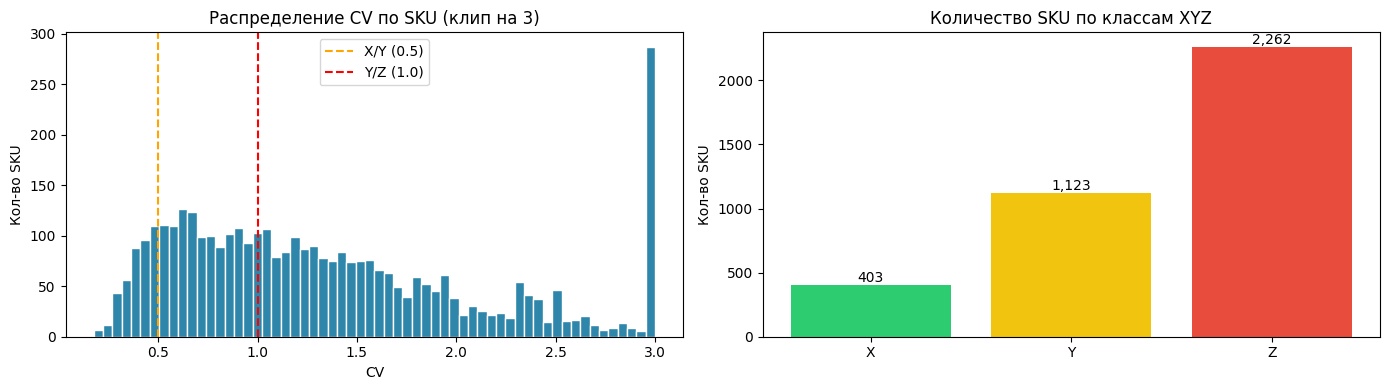

In [29]:
# ============================================================
# CELL 10 — CV distribution plot
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Гистограмма CV
axes[0].hist(xyz['cv'].clip(upper=3), bins=60, color='#2E86AB', edgecolor='white')
axes[0].axvline(0.5, color='orange', linestyle='--', label='X/Y (0.5)')
axes[0].axvline(1.0, color='red',    linestyle='--', label='Y/Z (1.0)')
axes[0].set_title('Распределение CV по SKU (клип на 3)')
axes[0].set_xlabel('CV')
axes[0].set_ylabel('Кол-во SKU')
axes[0].legend()

# Распределение по классам
colors = {'X': '#2ECC71', 'Y': '#F1C40F', 'Z': '#E74C3C'}
xyz_summary_sorted = xyz_summary.set_index('XYZ').loc[['X','Y','Z']]
axes[1].bar(xyz_summary_sorted.index, xyz_summary_sorted['SKUs'],
            color=[colors[k] for k in xyz_summary_sorted.index])
axes[1].set_title('Количество SKU по классам XYZ')
axes[1].set_ylabel('Кол-во SKU')
for i, v in enumerate(xyz_summary_sorted['SKUs']):
    axes[1].text(i, v, f'{v:,}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## Матрица ABC/XYZ

Совмещаем вклад в выручку (ABC) и стабильность спроса (XYZ).
Каждая из 9 ячеек требует своей стратегии управления запасами.

=== Количество SKU в матрице ===
XYZ    X    Y     Z
ABC                
A    254  308   269
B    122  376   464
C     27  439  1529

=== Доля выручки по ячейкам (%) ===
XYZ     X     Y     Z
ABC                  
A   29.60 29.10 21.30
B    2.10  5.80  7.10
C    0.10  1.70  3.10


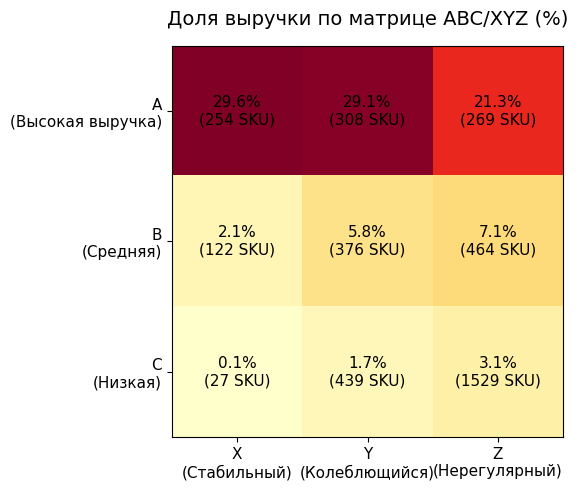

In [30]:
# ============================================================
# CELL 11 — ABC/XYZ Matrix (Fixed labels)
# ============================================================
# Объединяем ABC и XYZ
matrix = sku_abc[['StockCode', 'Revenue', 'Units', 'ABC']].merge(
    xyz[['XYZ']], left_on='StockCode', right_index=True, how='inner'
)
matrix['ABC_XYZ'] = matrix['ABC'] + matrix['XYZ']

# Сводная таблица: Количество SKU
pivot_sku = matrix.pivot_table(
    index='ABC', columns='XYZ', values='StockCode', aggfunc='count', fill_value=0
).loc[['A','B','C'], ['X','Y','Z']]

# Сводная таблица: Доля выручки (%)
pivot_rev = matrix.pivot_table(
    index='ABC', columns='XYZ', values='Revenue', aggfunc='sum', fill_value=0
).loc[['A','B','C'], ['X','Y','Z']]
pivot_rev_share = (pivot_rev / pivot_rev.values.sum() * 100).round(1)

print("=== Количество SKU в матрице ===")
print(pivot_sku)
print("\n=== Доля выручки по ячейкам (%) ===")
print(pivot_rev_share)

# Визуализация (Тепловая карта)
fig, ax = plt.subplots(figsize=(9, 5)) # Чуть увеличили размер
im = ax.imshow(pivot_rev_share.values, cmap='YlOrRd')

ax.set_xticks(range(3))
ax.set_yticks(range(3))

# ИСПРАВЛЕНИЕ: Переносим текст на новую строку
ax.set_xticklabels(['X\n(Стабильный)', 'Y\n(Колеблющийся)', 'Z\n(Нерегулярный)'], fontsize=11)
ax.set_yticklabels(['A\n(Высокая выручка)', 'B\n(Средняя)', 'C\n(Низкая)'], fontsize=11)

ax.set_title('Доля выручки по матрице ABC/XYZ (%)', fontsize=14, pad=15)

for i in range(3):
    for j in range(3):
        text = f"{pivot_rev_share.values[i, j]}%\n({pivot_sku.values[i, j]} SKU)"
        ax.text(j, i, text, ha="center", va="center", color="black", fontsize=11)

plt.tight_layout()
plt.show()

### Интерпретация матрицы и стратегии по ячейкам

Посмотрим на распределение выручки и количества SKU по группам. Цифры в скобках: `[Доля выручки] / [Количество SKU]`.

*   **AX (Ядро): 29.6% выручки / 254 SKU.** Высокая выручка, стабильный спрос.
    *Стратегия:* Всегда в наличии, жесткий контроль остатков, не выводим ни при каких условиях. Это наши локомотивы.
*   **AY (Сильные, но колеблющиеся): 29.1% выручки / 308 SKU.** Высокая выручка, спрос зависит от сезона или трендов.
    *Стратегия:* Держим достаточный страховой запас перед пиками (напр. осень), следим за трендами.
*   **AZ (Непредсказуемые локомотивы): 21.3% выручки / 269 SKU.** Высокая выручка, но хаотичный спрос. Часто это товары под оптовые заказы или редкие праздники.
    *Стратегия:* Риск кассовых разрывов или заморозки капитала. Нужен плотный мониторинг, закупаем строго под заказ или минимальными партиями.

*   **BX (Средние стабильные): 2.1% выручки / 122 SKU.**
    *Стратегия:* Стандартное управление. Отличные кандидаты для кросс-продаж (дополнения к товарам из AX).
*   **BY (Средние колеблющиеся): 5.8% выручки / 376 SKU.**
    *Стратегия:* Умеренные запасы, участвуют в промо-акциях для разгона спроса.
*   **BZ (Средние хаотичные): 7.1% выручки / 464 SKU.**
    *Стратегия:* Кандидаты на промо-акции, наборы (бандлы) или минимальные запасы. Не закупать большими партиями.

*   **CX (Слабые стабильные): 0.1% выручки / 27 SKU.**
    *Стратегия:* Микроскопическая выручка. Можно оставить только для "широты ассортимента", но закупать ровно столько, сколько продается.
*   **CY (Слабые колеблющиеся): 1.7% выручки / 439 SKU.**
    *Стратегия:* Балласт. Оставляем только те, что дают хоть какую-то маржу, остальные — в кандидаты на вывод.
*   **CZ (Хвост): 3.1% выручки / 1529 SKU.** Низкая выручка, нерегулярный спрос.
    *Стратегия:* **Главные кандидаты на вывод**. Занимают склад (1529 позиций!), занимают место в каталоге, но приносят лишь 3% денег. Именно из этой группы мы будем формировать список на сокращение.

## RFM-анализ клиентов

Оцениваем клиентскую базу по трём параметрам:
- **R**ecency — давность последней покупки (меньше = лучше)
- **F**requency — частота заказов (больше = лучше)
- **M**onetary — сумма покупок (больше = лучше)

In [31]:
# ============================================================
# CELL 12 — RFM Analysis
# ============================================================
# Дата "среза" для Recency (на день позже последней продажи)
snapshot_date = df_sales['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_sales.dropna(subset=['CustomerID']).groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

# Оценки от 1 до 4 (4 - лучший результат)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels=[1, 2, 3, 4]).astype(int)

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# Сегментация
def rfm_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4: return 'Champions'
    if r >= 3 and f >= 3: return 'Loyal'
    if r >= 3 and f <= 2: return 'Promising'
    if r <= 2 and f >= 3: return 'At Risk'
    if r <= 2 and f <= 2 and m >= 3: return 'Need Attention'
    return 'Lost'

rfm['Segment'] = rfm.apply(rfm_segment, axis=1)

rfm_summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Revenue=('Monetary', 'sum')
).reset_index()
rfm_summary['Customer_share_%'] = (rfm_summary['Customers'] / rfm_summary['Customers'].sum() * 100).round(1)
rfm_summary['Revenue_share_%'] = (rfm_summary['Revenue'] / rfm_summary['Revenue'].sum() * 100).round(1)
rfm_summary = rfm_summary.sort_values('Revenue', ascending=False)

print("=== Сводка по сегментам RFM ===")
print(rfm_summary.to_string(index=False))

=== Сводка по сегментам RFM ===
       Segment  Customers      Revenue  Customer_share_%  Revenue_share_%
     Champions        439 3,933,629.43             10.20            48.80
         Loyal       1051 2,184,136.94             24.50            27.10
       At Risk        655   919,717.42             15.30            11.40
Need Attention        257   370,419.18              6.00             4.60
          Lost       1209   336,429.60             28.20             4.20
     Promising        680   321,144.19             15.80             4.00


## Итоговый список кандидатов на вывод

**Логика отбора:**
1. Берем ячейку **CZ** (низкая выручка, нерегулярный спрос).
2. Сортируем по выручке по возрастанию.
3. Отбираем ~20% от всего ассортимента (758 SKU).
4. Считаем, сколько выручки и заказов мы потеряем.

In [32]:
# ============================================================
# CELL 13 — Candidate List & Effect Evaluation
# ============================================================
# 1. Определяем, сколько SKU нужно сократить (20%)
total_skus = len(sku_abc)
target_cut_count = int(total_skus * 0.20)
print(f"Всего SKU: {total_skus:,}. Цель по сокращению (20%): {target_cut_count:,} SKU.")

# 2. Берем только CZ и сортируем по выручке (худшие наверх)
cz_skus = matrix[matrix['ABC_XYZ'] == 'CZ'].sort_values('Revenue', ascending=True)
print(f"Всего в группе CZ: {len(cz_skus):,} SKU.")

# 3. Формируем список на удаление
to_drop = cz_skus.head(target_cut_count).copy()

# 4. Считаем потери
lost_revenue = to_drop['Revenue'].sum()
lost_units = to_drop['Units'].sum()
total_revenue = matrix['Revenue'].sum()

print("\n=== ОЦЕНКА ЭФФЕКТА ОТ СОКРАЩЕНИЯ ===")
print(f"Количество SKU к выводу:   {len(to_drop):,} (20.0% ассортимента)")
print(f"Потеря выручки:            £{lost_revenue:,.2f} ({lost_revenue/total_revenue*100:.2f}% от общей)")
print(f"Потеря единиц товара:      {lost_units:,} штук")

# 5. Проверяем, кто покупал эти товары (связь с RFM)
# Смотрим долю выручки от клиентов из сегмента Champions среди этих SKU
skus_to_drop = to_drop['StockCode'].tolist()
champions_ids = rfm[rfm['Segment'] == 'Champions']['CustomerID'].tolist()

drop_sales = df_sales[df_sales['StockCode'].isin(skus_to_drop)]
champ_rev = drop_sales[drop_sales['CustomerID'].isin(champions_ids)]['Revenue'].sum()

print(f"Выручка от Champions в этих SKU: £{champ_rev:,.2f} ({champ_rev/lost_revenue*100:.1f}% от теряемой)")

# 6. Выводим первые 15 строк для наглядности
print("\nТоп-15 самых неэффективных SKU (кандидаты на вывод):")
print(to_drop[['StockCode', 'Revenue', 'Units', 'ABC_XYZ']].head(15).to_string(index=False))

# 7. Сохраняем полный список в файл
to_drop.to_csv(os.path.join(PROJECT_DIR, 'skus_to_drop.csv'), index=False)
print(f"\nПолный список из {len(to_drop)} SKU сохранен в 'skus_to_drop.csv'")

Всего SKU: 3,788. Цель по сокращению (20%): 757 SKU.
Всего в группе CZ: 1,529 SKU.

=== ОЦЕНКА ЭФФЕКТА ОТ СОКРАЩЕНИЯ ===
Количество SKU к выводу:   757 (20.0% ассортимента)
Потеря выручки:            £25,387.45 (0.27% от общей)
Потеря единиц товара:      19,840 штук
Выручка от Champions в этих SKU: £5,264.57 (20.7% от теряемой)

Топ-15 самых неэффективных SKU (кандидаты на вывод):
StockCode  Revenue  Units ABC_XYZ
    84227     0.42      1      CZ
    21268     0.84      2      CZ
    90084     0.85      1      CZ
   84201C     0.95      5      CZ
   84206B     0.95      5      CZ
    84990     1.10      2      CZ
    21009     1.25      1      CZ
    85225     1.25      1      CZ
   35597A     1.25      1      CZ
    37461     1.25      1      CZ
   35597B     1.25      1      CZ
   84569C     1.25      1      CZ
   84743C     1.25      1      CZ
    84977     1.25      1      CZ
   84206C     1.52      8      CZ

Полный список из 757 SKU сохранен в 'skus_to_drop.csv'


## Итоговый вывод и бизнес-эффект

Перед нами стояла задача предложить обоснованный список кандидатов на вывод (~20% SKU) и оценить эффект от этого решения.

### Результаты анализа
1. **Правило Парето подтверждено:** 831 SKU (22% ассортимента) генерируют 80% выручки (£7.57 млн).
2. **Клиентская база сконцентрирована:** Сегменты "Champions" и "Loyal" (35% клиентов) приносят 75.9% выручки.
3. **Мертвый груз найден:** Ячейка **CZ** содержит 1,529 товаров, которые дают лишь 3.1% выручки.

### Предлагаемое решение
Мы предлагаем вывести **757 SKU** (ровно 20% ассортимента). Отбор производился из ячейки **CZ** (худшие по выручке и нерегулярные по спросу).

### Оценка эффекта от сокращения
*   **Потеря выручки:** £25,387.45 (**всего 0.27%** от общей выручки в £9.47 млн).
*   **Освобождение склада:** 19,840 единиц товара.
*   **Влияние на лояльных клиентов:** Потеря выручки от сегмента "Champions" составит £5,264 (0.13% от их общего вклада). Клиенты не ощутят ущерба, так как эти товары имеют крайне низкую частоту покупок.

**Бизнес-вывод:** Вывод 20% ассортимента освободит складские мощности и сфокусирует внимание на локомотивных товарах (AX, AY, AZ), при этом финансовые потери бизнеса будут минимальны и незаметны для ключевых клиентов. Список сохранен в файл `skus_to_drop.csv`.

# Анализ ассортимента методом ABC/XYZ

## Бизнес-задача
Оценить структуру ассортимента британского интернет-магазина подарков и товаров для дома.
Руководство рассматривает сокращение ~20% SKU для оптимизации складских запасов.
Задача — предложить обоснованный список кандидатов на вывод и оценить финансовый эффект.

## Данные
- **Источник:** [Online Retail II](https://archive.ics.uci.edu/ml/datasets/Online+Retail+II) (UCI)
- **Период анализа:** 2010-12-01 — 2011-11-30 (12 полных месяцев, включая полный сезонный цикл)
- **После очистки:** 496 657 строк, 3 788 уникальных SKU, 18 859 заказов, £9 471 200.61 выручки

## Методология очистки данных
- Удалены отмены (InvoiceNo, начинающиеся с `C`).
- Удалены service-коды (доставка, банковские сборы и т.д.).
- Удалены «фантомные отмены» — sale-строки, полностью компенсированные отменой того же клиента, SKU, количества и даты (722 строки).
- Отфильтрованы нестандартные StockCode (включая подарочные сертификаты) с помощью regex.

## Ключевые результаты анализа

### 1. ABC-анализ
- **Класс A:** 831 SKU (21.9%) — приносят 80% выручки.
- **Класс B:** 962 SKU (25.4%) — приносят 15% выручки.
- **Класс C:** 1995 SKU (52.7%) — приносят всего 5% выручки.

### 2. XYZ-анализ
- **X (стабильный спрос):** 403 SKU.
- **Y (колеблющийся):** 1123 SKU.
- **Z (нерегулярный):** 2262 SKU.

### 3. RFM-анализ клиентов
- Сегмент **Champions** (10.2% клиентов) приносит 48.8% выручки.
- Сегмент **Loyal** (24.5% клиентов) приносит 27.1% выручки.

## Главный вывод и эффект от сокращения
Для сокращения 20% ассортимента были отобраны **757 SKU** из самой слабой группы матрицы **CZ** (низкая выручка + нерегулярный спрос).

**Финансовый эффект:**
- Потеря выручки: **£25,387.45** (всего **0.27%** от общей).
- Освобождение склада: **19,840** единиц товара.
- Влияние на ключевых клиентов (Champions): минимальное (£5,264 потерь при их вкладе в £3.9 млн).

Вывод: предложенная оптимизация безопасна для бизнеса и освобождает ресурсы для развития локомотивных товаров. Полный список 757 SKU находится в файле `skus_to_drop.csv`.

## Стек
- Python (Pandas, NumPy)
- Matplotlib
- Google Colab

## Автор
Павлов Владимир